In [1]:
# Environment setup (run once, from the repo root - NOT in this notebook):
#
#   python -m venv .venv
#   .venv\Scripts\activate          # Windows
#   source .venv/bin/activate        # macOS / Linux
#   pip install -r requirements.txt
#
# All dependencies are pinned in requirements.txt.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from lifelines import KaplanMeierFitter
from lifelines import CoxPHFitter

from pathlib import Path

# Resolve the data directory whether this notebook is run from the repo root
# or from src/. Keeps the notebook portable across machines.
DATA_DIR = next(p for p in (Path("data"), Path("../data")) if p.is_dir())

RAW_CSV       = DATA_DIR / "Telco_Customer_Churn.csv"
PROCESSED_CSV = DATA_DIR / "processed_df.csv"
ENCODED_CSV   = DATA_DIR / "survival_df_encoded.csv"


In [3]:
og_data = pd.read_csv(RAW_CSV)
og_data.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [4]:
og_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [5]:
df = og_data.copy()

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:

df.columns = df.columns.str.strip()

In [8]:
# Target
df['event'] = np.where(df['Churn'] == 'Yes',1,0)
df['duration'] = df['tenure']

In [9]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors = 'coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

In [10]:
# dropping unwanted columns

df = df.drop(columns = ['Churn','tenure','customerID'])
df.to_csv(PROCESSED_CSV)


In [11]:
df = pd.read_csv(PROCESSED_CSV, index_col = 0)

In [12]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,event,duration
0,Female,0,Yes,No,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,1
1,Male,0,No,No,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0,34
2,Male,0,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,2
3,Male,0,No,No,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,45
4,Female,0,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,2


In [13]:
# converting categorical variables using one-hot encode

cat_cols = df.select_dtypes(include= 'object').columns

df_encoded = pd.get_dummies(df, columns= cat_cols, drop_first= False, dtype=int)

In [14]:
final_df = df_encoded.copy()

In [15]:
final_df.to_csv(ENCODED_CSV)

In [16]:
survival_df_enc = pd.read_csv(ENCODED_CSV, index_col= 0)

In [17]:
survival_df_enc.head()

,SeniorCitizen,MonthlyCharges,TotalCharges,event,duration,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,29.85,29.85,0,1,1,0,0,1,1,...,0,1,0,0,0,1,0,0,1,0
1,0,56.95,1889.50,0,34,0,1,1,0,1,...,0,0,1,0,1,0,0,0,0,1
2,0,53.85,108.15,1,2,0,1,1,0,1,...,0,1,0,0,0,1,0,0,0,1
3,0,42.30,1840.75,0,45,0,1,1,0,1,...,0,0,1,0,1,0,1,0,0,0
4,0,70.70,151.65,1,2,1,0,1,0,1,...,0,1,0,0,0,1,0,0,1,0


A Kaplan-Meier (KM) curve is a step-like graph showing the probability of survival over time, used in survival analysis to estimate how long subjects remain event-free (like surviving a disease or a machine part functioning) while accounting for censored data, where follow-up is incomplete. It plots time (X-axis) against the proportion of survivors (Y-axis), showing survival probability as horizontal steps that drop at each event, with tick marks indicating censored data points where the event status is unknown.

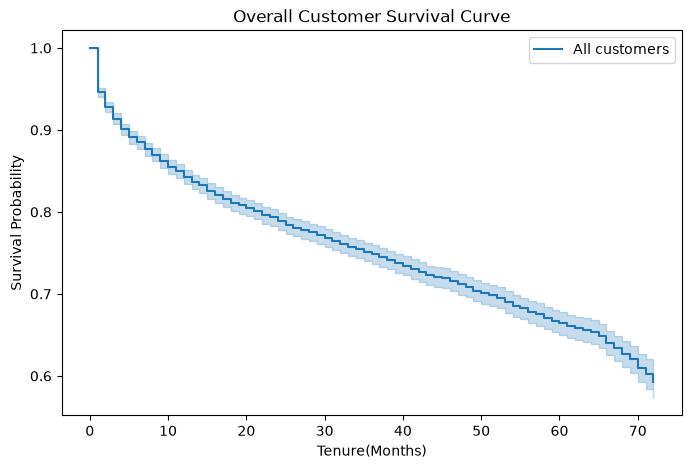

In [18]:
# How does a customer survival decline over time?

plt.figure(figsize=(8,5))
kmf = KaplanMeierFitter()
kmf.fit(durations=df['duration'],
                      event_observed = df['event'],
                      label = 'All customers')

kmf.plot_survival_function()
plt.title('Overall Customer Survival Curve')
plt.xlabel('Tenure(Months)')
plt.ylabel('Survival Probability')
plt.show()

This tells us that most of the customer churn in the starting 10 months tenure.

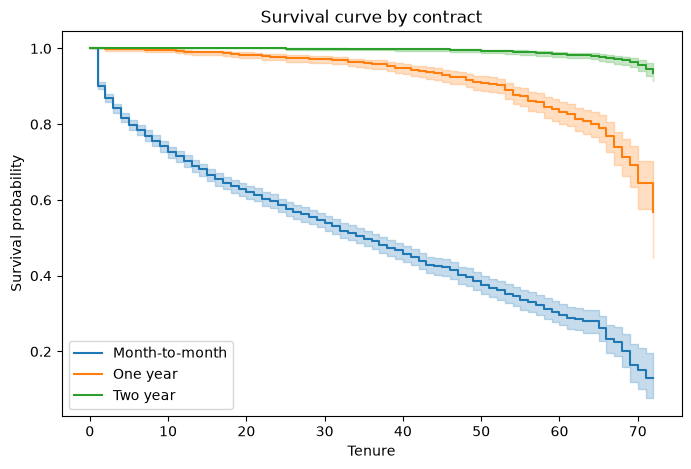

In [19]:
plt.figure(figsize=(8,5))

for contract in df['Contract'].unique():
    mask = df['Contract'] == contract
    kmf.fit(df.loc[mask, 'duration'],
            df.loc[mask, 'event'],
            label = contract)
    kmf.plot_survival_function()

plt.title('Survival curve by contract')
plt.xlabel('Tenure')
plt.ylabel('Survival probability')
plt.legend()
plt.show()

Month-to-Month customers churn significantly earlier.

In [20]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,event,duration
0,Female,0,Yes,No,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,1
1,Male,0,No,No,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0,34
2,Male,0,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,2
3,Male,0,No,No,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,45
4,Female,0,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,2


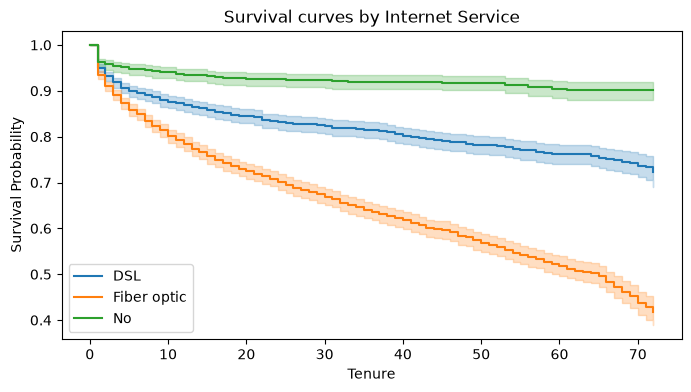

In [21]:
plt.figure(figsize=(8,4))

for method in df['InternetService'].unique():
    mask = df['InternetService'] == method
    kmf.fit(
        df.loc[mask, 'duration'],
        df.loc[mask, 'event'],
        label = method
    )
    kmf.plot_survival_function()

plt.title('Survival curves by Internet Service')
plt.xlabel('Tenure')
plt.ylabel('Survival Probability')
plt.legend()
plt.show()


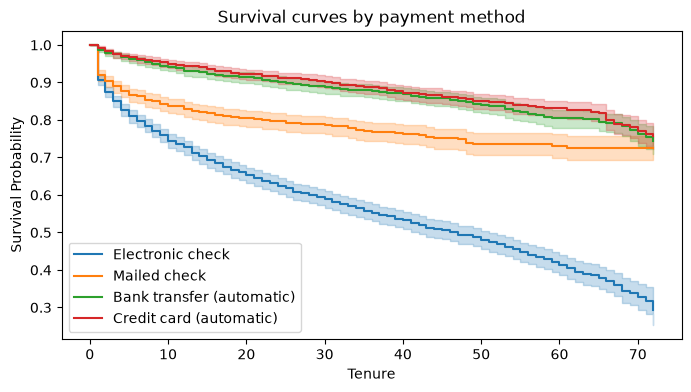

In [22]:
plt.figure(figsize=(8,4))

for method in df['PaymentMethod'].unique():
    mask = df['PaymentMethod'] == method
    kmf.fit(
        df.loc[mask, 'duration'],
        df.loc[mask, 'event'],
        label = method
    )
    kmf.plot_survival_function()

plt.title('Survival curves by payment method')
plt.xlabel('Tenure')
plt.ylabel('Survival Probability')
plt.legend()
plt.show()


Electronic check users are more likely to churn, while auto-pay users have significantly longer survival

In [23]:
df['tenure_bucket'] = pd.cut(
    df['duration'],
    bins = [0,6,12,24,48,72],
    labels = ['0-6','6-12','12-24','24-48','48+']
)

df.groupby('tenure_bucket')['event'].mean()

C:\Users\snehi\AppData\Local\Temp\ipykernel_28576\1932506218.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('tenure_bucket')['event'].mean()


tenure_bucket
0-6      0.533333
6-12     0.358865
12-24    0.287109
24-48    0.203890
48+      0.095132
Name: event, dtype: float64

0-6 months tenure has the highest probability of churn

from all this we can say:
- churn is time dependent
- Contract and payment method strongly influence churn timing
- Retention should focus on early lifecycle customers

#### Survival Modeling with Cox Proportional Hazards Model
##### The Cox Proportional Hazards Model is a widely used regression model in survival analysis that examines how different factors (covariates) affect the time until an event (like death, failure, or recovery) occurs, without requiring assumptions about the underlying event distribution.
##### It works by modeling the hazard rate (instantaneous risk of the event) as a function of covariates, assuming the effect of these factors remains constant (proportional) over time, allowing estimation of hazard ratios (HRs) that quantify the increased or decreased risk associated with each factor, such as age, gender, or treatment. 

In [24]:
cols = ['duration','event'] + [
    c for c in survival_df_enc.columns if c not in ['duration','event']
]

survival_df_enc = survival_df_enc[cols]

In [25]:
survival_df_enc.head()

,duration,event,SeniorCitizen,MonthlyCharges,TotalCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,1,0,0,29.85,29.85,1,0,0,1,1,...,0,1,0,0,0,1,0,0,1,0
1,34,0,0,56.95,1889.50,0,1,1,0,1,...,0,0,1,0,1,0,0,0,0,1
2,2,1,0,53.85,108.15,0,1,1,0,1,...,0,1,0,0,0,1,0,0,0,1
3,45,0,0,42.30,1840.75,0,1,1,0,1,...,0,0,1,0,1,0,1,0,0,0
4,2,1,0,70.70,151.65,1,0,1,0,1,...,0,1,0,0,0,1,0,0,1,0


In [26]:
survival_df_enc.isna().sum()

duration                                   0
event                                      0
SeniorCitizen                              0
MonthlyCharges                             0
TotalCharges                               0
gender_Female                              0
gender_Male                                0
Partner_No                                 0
Partner_Yes                                0
Dependents_No                              0
Dependents_Yes                             0
PhoneService_No                            0
PhoneService_Yes                           0
MultipleLines_No                           0
MultipleLines_No phone service             0
MultipleLines_Yes                          0
InternetService_DSL                        0
InternetService_Fiber optic                0
InternetService_No                         0
OnlineSecurity_No                          0
OnlineSecurity_No internet service         0
OnlineSecurity_Yes                         0
OnlineBack

In [27]:
cph = CoxPHFitter(penalizer=0.1)  #Regularization

cph.fit(survival_df_enc,
        duration_col = 'duration',
        event_col = 'event')

cph.print_summary()

<lifelines.CoxPHFitter: fitted with 7043 total observations, 5174 right-censored observations>
             duration col = 'duration'
                event col = 'event'
                penalizer = 0.1
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 7043
number of events observed = 1869
   partial log-likelihood = -13794.40
         time fit was run = 2026-09-09 18:58:39 UTC

---
                                         coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                                
SeniorCitizen                            0.01      1.01      0.05           -0.08            0.11                0.92                1.12
MonthlyCharges                           0.00      1.00      0.00           -0.00            0.00                1.00                1.00
TotalCharges                            -0.00      1.00      0.00           -0.00           -0.00                1.00                1.00
gender_Female                            0.02      1.02      0.06           -0.09            0.13                0.91                1.14
gender_Male                             -0.02      0.98      0.06           -0.13            0.09                0.87                1.09
Partner_No                               0.17      1.19      0.06            0.06            0.29                1.06                1.33
Partner_Yes                             -0.17      0.84      0.06           -0.29           -0.06                0.75                0.94
Dependents_No                            0.07      1.07      0.06           -0.06            0.20                0.94                1.22
Dependents_Yes                          -0.07      0.93      0.06           -0.20            0.06                0.82                1.06
PhoneService_No                         -0.05      0.95      0.11           -0.26            0.17                0.77                1.18
PhoneService_Yes                         0.05      1.05      0.11           -0.17            0.26                0.85                1.30
MultipleLines_No                         0.11      1.11      0.06           -0.00            0.22                1.00                1.25
MultipleLines_No phone service          -0.05      0.95      0.11           -0.26            0.17                0.77                1.18
MultipleLines_Yes                       -0.09      0.91      0.06           -0.21            0.02                0.81                1.02
InternetService_DSL                     -0.22      0.80      0.06           -0.34           -0.10                0.71                0.91
InternetService_Fiber optic              0.29      1.34      0.06            0.17            0.41                1.18                1.51
InternetService_No                      -0.13      0.88      0.09           -0.30            0.05                0.74                1.05
OnlineSecurity_No                        0.27      1.30      0.06            0.15            0.38                1.16                1.47
OnlineSecurity_No internet service      -0.13      0.88      0.09           -0.30            0.05                0.74                1.05
OnlineSecurity_Yes                      -0.22      0.80      0.06           -0.34           -0.10                0.71                0.91
OnlineBackup_No                          0.22      1.25      0.06            0.11            0.34                1.12                1.40
OnlineBackup_No internet service        -0.13      0.88      0.09           -0.30            0.05                0.74                1.05
OnlineBackup_Yes                        -0.15      0.86      0.06           -0.27           -0.03                0.77                0.97
DeviceProtection_No                      0.14      1.15      0.06            0.02            0.26                1.03  

- InternetService_Fiber optic = HR = 1.6
- Fiber customer churn 60% faster, controlling for other factors

- Contract_Two year = HR = .35
- Two year contract reduces churn risk by 65%

In [28]:
# Model validation

cph.concordance_index_

np.float64(0.9026620484063158)

In [29]:
# Assumption check

cph.check_assumptions(
    survival_df_enc,
    p_value_threshold=0.05
)

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'MonthlyCharges' failed the non-proportional test: p-value is 0.0301.

   Advice 1: the functional form of the variable 'MonthlyCharges' might be incorrect. That is, there
may be non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'MonthlyCharges' using pd.cut, and then specify it in
`strata=['MonthlyCharges', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


2. Variable 'InternetService_Fiber optic' failed the non-proportional test: p-value is 0.0431.

   Advice: with so few unique values (only 2), you can include `strata=['InternetService_Fiber
optic', ...]` in the call in `.fit`. See documentation in link [E] below.

3. Variable 'StreamingTV_Yes' failed the non-proportional test: 

[]

In [30]:
# Time varying effects for violation variables

violating_vars = [
    'Contract_One year',
    'Contract_Two year',
    'InternetService_Fiber optic',
    'MonthlyCharges',
    'MultipleLines_Yes',
    'StreamingTV_Yes',
    'StreamingMovies_Yes',
    'TotalCharges'
]

for var in violating_vars:
    survival_df_enc[f'{var}_log_time'] = survival_df_enc[var] * np.log(df['duration'])

In [31]:
survival_df_enc = survival_df_enc.fillna(0)

In [32]:
survival_df_enc.isna().sum()

duration                                   0
event                                      0
SeniorCitizen                              0
MonthlyCharges                             0
TotalCharges                               0
gender_Female                              0
gender_Male                                0
Partner_No                                 0
Partner_Yes                                0
Dependents_No                              0
Dependents_Yes                             0
PhoneService_No                            0
PhoneService_Yes                           0
MultipleLines_No                           0
MultipleLines_No phone service             0
MultipleLines_Yes                          0
InternetService_DSL                        0
InternetService_Fiber optic                0
InternetService_No                         0
OnlineSecurity_No                          0
OnlineSecurity_No internet service         0
OnlineSecurity_Yes                         0
OnlineBack

In [33]:
np.isinf(survival_df_enc).sum().sort_values(ascending = False)

TotalCharges_log_time                      11
MonthlyCharges_log_time                    11
Contract_Two year_log_time                 10
MultipleLines_Yes_log_time                  4
StreamingTV_Yes_log_time                    4
Contract_One year_log_time                  1
StreamingMovies_Yes_log_time                1
gender_Male                                 0
Partner_Yes                                 0
Dependents_No                               0
Dependents_Yes                              0
PhoneService_No                             0
PhoneService_Yes                            0
MultipleLines_No                            0
MultipleLines_No phone service              0
Partner_No                                  0
duration                                    0
event                                       0
SeniorCitizen                               0
MonthlyCharges                              0
TotalCharges                                0
gender_Female                     

In [34]:
survival_df_enc.replace([np.inf, -np.inf], np.nan, inplace=True)

In [35]:
survival_df_enc = survival_df_enc.fillna(0)

In [36]:
cph_tv = CoxPHFitter(penalizer=0.1)

cph_tv.fit(survival_df_enc,
           duration_col = 'duration',
           event_col = 'event')

cph_tv.print_summary()

<lifelines.CoxPHFitter: fitted with 7043 total observations, 5174 right-censored observations>
             duration col = 'duration'
                event col = 'event'
                penalizer = 0.1
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 7043
number of events observed = 1869
   partial log-likelihood = -13369.69
         time fit was run = 2026-09-09 18:58:42 UTC

---
                                         coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                                
SeniorCitizen                            0.05      1.05      0.05           -0.05            0.14                0.95                1.15
MonthlyCharges                           0.01      1.01      0.00            0.00            0.01                1.00                1.01
TotalCharges                            -0.00      1.00      0.00           -0.00           -0.00                1.00                1.00
gender_Female                            0.02      1.02      0.06           -0.10            0.13                0.91                1.14
gender_Male                             -0.02      0.98      0.06           -0.13            0.10                0.88                1.10
Partner_No                               0.13      1.14      0.06            0.01            0.24                1.01                1.27
Partner_Yes                             -0.13      0.88      0.06           -0.24           -0.01                0.78                0.99
Dependents_No                            0.07      1.07      0.07           -0.06            0.20                0.94                1.22
Dependents_Yes                          -0.07      0.93      0.07           -0.20            0.06                0.82                1.06
PhoneService_No                         -0.17      0.84      0.11           -0.39            0.04                0.68                1.04
PhoneService_Yes                         0.17      1.19      0.11           -0.04            0.39                0.96                1.47
MultipleLines_No                        -0.04      0.96      0.06           -0.16            0.08                0.85                1.08
MultipleLines_No phone service          -0.17      0.84      0.11           -0.39            0.04                0.68                1.04
MultipleLines_Yes                        0.10      1.11      0.06           -0.02            0.22                0.98                1.25
InternetService_DSL                     -0.39      0.68      0.06           -0.51           -0.26                0.60                0.77
InternetService_Fiber optic              0.50      1.64      0.06            0.37            0.62                1.45                1.86
InternetService_No                      -0.21      0.81      0.09           -0.38           -0.04                0.69                0.97
OnlineSecurity_No                        0.25      1.29      0.06            0.14            0.37                1.15                1.45
OnlineSecurity_No internet service      -0.21      0.81      0.09           -0.38           -0.04                0.69                0.97
OnlineSecurity_Yes                      -0.14      0.87      0.06           -0.26           -0.02                0.77                0.98
OnlineBackup_No                          0.19      1.21      0.06            0.07            0.30                1.08                1.36
OnlineBackup_No internet service        -0.21      0.81      0.09           -0.38           -0.04                0.69                0.97
OnlineBackup_Yes                        -0.05      0.95      0.06           -0.17            0.07                0.85                1.07
DeviceProtection_No                      0.11      1.12      0.06           -0.00            0.23                1.00  

In [37]:
cph_tv.check_assumptions(survival_df_enc, p_value_threshold=0.05)

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'TotalCharges' failed the non-proportional test: p-value is 0.0003.

   Advice 1: the functional form of the variable 'TotalCharges' might be incorrect. That is, there
may be non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'TotalCharges' using pd.cut, and then specify it in
`strata=['TotalCharges', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


2. Variable 'Contract_One year' failed the non-proportional test: p-value is 0.0198.

   Advice: with so few unique values (only 2), you can include `strata=['Contract_One year', ...]`
in the call in `.fit`. See documentation in link [E] below.

3. Variable 'InternetService_Fiber optic_log_time' failed the non-proportional test: p-value

[]

all the variables are somewhat fixed but the Total charges variables is still causing violations, since we Total charges is just Monthly charges X tenure, i've decide to drop the columns completely from the data

In [38]:
survival_df_enc.drop(columns=['TotalCharges','TotalCharges_log_time'],inplace = True)

In [39]:
cph_tv = CoxPHFitter(penalizer=0.1)

cph_tv.fit(survival_df_enc,
           duration_col = 'duration',
           event_col = 'event')

cph_tv.print_summary()

<lifelines.CoxPHFitter: fitted with 7043 total observations, 5174 right-censored observations>
             duration col = 'duration'
                event col = 'event'
                penalizer = 0.1
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 7043
number of events observed = 1869
   partial log-likelihood = -13582.46
         time fit was run = 2026-09-09 18:58:46 UTC

---
                                         coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                                                
SeniorCitizen                            0.04      1.04      0.05           -0.06            0.13                0.94                1.14
MonthlyCharges                           0.01      1.01      0.00            0.00            0.01                1.00                1.01
gender_Female                            0.02      1.02      0.06           -0.09            0.13                0.91                1.14
gender_Male                             -0.02      0.98      0.06           -0.13            0.09                0.88                1.10
Partner_No                               0.16      1.17      0.06            0.04            0.27                1.04                1.31
Partner_Yes                             -0.16      0.85      0.06           -0.27           -0.04                0.76                0.96
Dependents_No                            0.07      1.07      0.06           -0.06            0.20                0.94                1.22
Dependents_Yes                          -0.07      0.93      0.06           -0.20            0.06                0.82                1.06
PhoneService_No                         -0.14      0.87      0.11           -0.36            0.07                0.70                1.07
PhoneService_Yes                         0.14      1.16      0.11           -0.07            0.36                0.93                1.43
MultipleLines_No                        -0.05      0.95      0.06           -0.17            0.06                0.84                1.07
MultipleLines_No phone service          -0.14      0.87      0.11           -0.36            0.07                0.70                1.07
MultipleLines_Yes                        0.11      1.11      0.06           -0.01            0.23                0.99                1.25
InternetService_DSL                     -0.41      0.66      0.06           -0.54           -0.29                0.58                0.75
InternetService_Fiber optic              0.50      1.65      0.06            0.37            0.62                1.45                1.86
InternetService_No                      -0.17      0.84      0.09           -0.34           -0.00                0.71                1.00
OnlineSecurity_No                        0.28      1.32      0.06            0.16            0.40                1.18                1.49
OnlineSecurity_No internet service      -0.17      0.84      0.09           -0.34           -0.00                0.71                1.00
OnlineSecurity_Yes                      -0.20      0.82      0.06           -0.32           -0.08                0.72                0.93
OnlineBackup_No                          0.23      1.26      0.06            0.12            0.35                1.12                1.42
OnlineBackup_No internet service        -0.17      0.84      0.09           -0.34           -0.00                0.71                1.00
OnlineBackup_Yes                        -0.12      0.88      0.06           -0.24           -0.01                0.79                0.99
DeviceProtection_No                      0.14      1.15      0.06            0.02            0.25                1.02                1.29
DeviceProtection_No internet service    -0.17      0.84      0.09           -0.34           -0.00                0.71  

In [40]:
cph_tv.check_assumptions(survival_df_enc, p_value_threshold=0.05)

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'Contract_One year' failed the non-proportional test: p-value is 0.0243.

   Advice: with so few unique values (only 2), you can include `strata=['Contract_One year', ...]`
in the call in `.fit`. See documentation in link [E] below.

2. Variable 'Contract_Two year_log_time' failed the non-proportional test: p-value is 0.0426.

   Advice 1: the functional form of the variable 'Contract_Two year_log_time' might be incorrect.
That is, there may be non-linear terms missing. The proportional hazard test used is very sensitive
to incorrect functional forms. See documentation in link [D] below on how to specify a functional
form.

   Advice 2: try binning the variable 'Contract_Two year_log_time' using pd.cut, and then specify it
in `strata=['Contract_Two year_log_time', ...]` in the call in `.fit`. See documentation in link [B]
below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


3. Variable 'InternetService_Fiber o

[]

<Axes: title={'center': 'Predicted survival curve for customer'}>

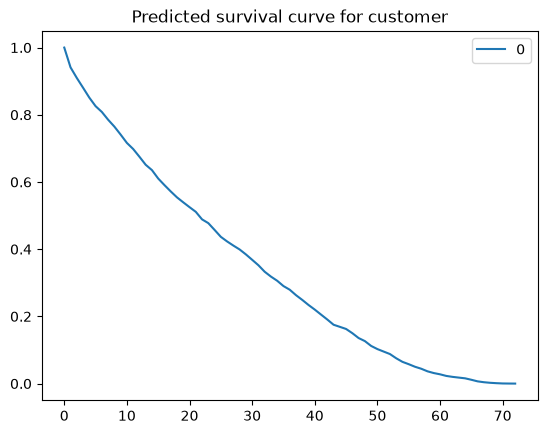

In [41]:
# individual survival prediction

sample_customer = survival_df_enc.drop(columns=['duration','event']).iloc[[0]]

survival_curve = cph_tv.predict_survival_function(sample_customer)

survival_curve.plot(title = 'Predicted survival curve for customer')

In [42]:
def churn_probability_within(model, X, months):
    surv = model.predict_survival_function(X, times = [months])
    return 1 - surv.T.squeeze()

survival_df_enc['churn_3m'] = churn_probability_within(cph_tv,
                                                      survival_df_enc.drop(columns = ['duration','event']),
                                                      3)

survival_df_enc['churn_6m']= churn_probability_within(cph_tv,
                                                      survival_df_enc.drop(columns = ['duration','event']),
                                                      6)

now we have the probability of churn for each customer.

In [43]:
survival_df_enc['expected_life']= cph_tv.predict_expectation(
    survival_df_enc.drop(columns=['duration','event'])
)

#### Customer lifetime value

CLV ~ Monthly revenue X Expected remaining lifetime

In [44]:
survival_df_enc['MonthlyCharges'] = df['MonthlyCharges'].values

In [45]:
survival_df_enc['CLV'] = (survival_df_enc['MonthlyCharges'] * survival_df_enc['expected_life'])

In [46]:
survival_df_enc['CLV'].describe()

count    7043.000000
mean     2977.577115
std      2239.337548
min       102.373839
25%      1176.280474
50%      2112.597352
75%      4698.660416
max      8491.180819
Name: CLV, dtype: float64

<Axes: ylabel='Frequency'>

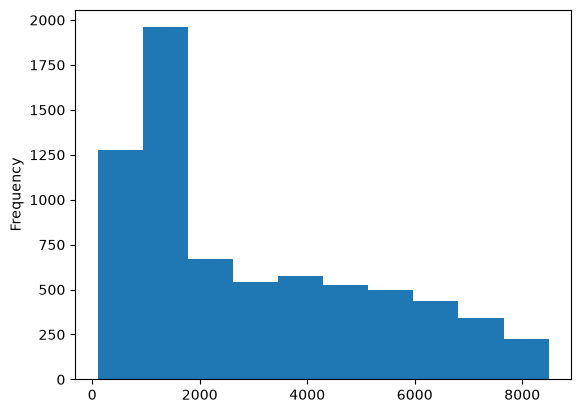

In [47]:
survival_df_enc['CLV'].plot(kind = 'hist')

In [48]:
survival_df_enc['CLV_segment'] = pd.qcut(
    survival_df_enc['CLV'],
        q = [0,0.5,0.8,1.0],
        labels = ['Low','Medium','High']
)

In [49]:
survival_df_enc["risk_segment"] = pd.qcut(
    survival_df_enc["churn_6m"],
    q=[0, 0.7, 0.9, 1.0],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

In [50]:
def retention_action(row):
    if row["CLV_segment"] == "High" and row["risk_segment"] == "High Risk":
        return "Immediate Retention"
    if row["CLV_segment"] == "High" and row["risk_segment"] == "Low Risk":
        return "Monitor"
    if row["CLV_segment"] == "Low" and row["risk_segment"] == "High Risk":
        return "No Action"
    return "Ignore"

survival_df_enc["action"] = survival_df_enc.apply(retention_action, axis=1)


#### Visualization

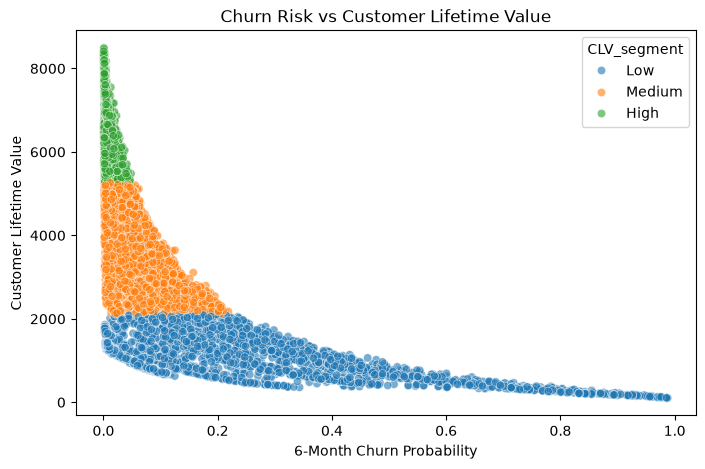

In [51]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=survival_df_enc,
    x="churn_6m",
    y="CLV",
    hue="CLV_segment",
    alpha=0.6
)
plt.title("Churn Risk vs Customer Lifetime Value")
plt.xlabel("6-Month Churn Probability")
plt.ylabel("Customer Lifetime Value")
plt.show()


##### So, who should we spend money on to prevent churn? (profit maximization)

#### Core formula:

` Expected value = (CLV X Retention success probability) - Retention cost`

only intervene if: 
`Expected value > 0`

In [52]:
#assumptions

Retention_cost = 500      

def retention_probability(risk_segment):
    if risk_segment == 'High Risk':
        return 0.4
    elif risk_segment == 'Medium Risk':
        return 0.25
    else:
        return 0.1

In [53]:
survival_df_enc['retention_success_prob'] = survival_df_enc['risk_segment'].apply(retention_probability)

In [54]:
survival_df_enc['retention_success_prob'] = survival_df_enc['retention_success_prob'].astype('float')
survival_df_enc.dtypes


duration                                      int64
event                                         int64
SeniorCitizen                                 int64
MonthlyCharges                              float64
gender_Female                                 int64
gender_Male                                   int64
Partner_No                                    int64
Partner_Yes                                   int64
Dependents_No                                 int64
Dependents_Yes                                int64
PhoneService_No                               int64
PhoneService_Yes                              int64
MultipleLines_No                              int64
MultipleLines_No phone service                int64
MultipleLines_Yes                             int64
InternetService_DSL                           int64
InternetService_Fiber optic                   int64
InternetService_No                            int64
OnlineSecurity_No                             int64
OnlineSecuri

In [55]:
# Expected value

survival_df_enc['expected_retention_value'] = (survival_df_enc['CLV'] * survival_df_enc['retention_success_prob'])

In [56]:
survival_df_enc['net_value'] = (survival_df_enc['expected_retention_value'] - Retention_cost)

In [57]:
survival_df_enc.sort_values(by = 'net_value', ascending= False)

,duration,event,SeniorCitizen,MonthlyCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,...,churn_3m,churn_6m,expected_life,CLV,CLV_segment,risk_segment,action,retention_success_prob,expected_retention_value,net_value
2265,12,1,0,112.95,0,1,1,0,1,0,...,0.076931,0.125258,32.250680,3642.714321,Medium,Medium Risk,Ignore,0.25,910.678580,410.678580
880,10,1,0,110.10,0,1,1,0,1,0,...,0.074093,0.120758,32.954712,3628.313804,Medium,Medium Risk,Ignore,0.25,907.078451,407.078451
1132,11,1,1,104.05,1,0,0,1,1,0,...,0.071768,0.117063,33.552295,3491.116278,Medium,Medium Risk,Ignore,0.25,872.779070,372.779070
4701,21,0,1,104.35,0,1,1,0,1,0,...,0.075327,0.122716,32.645287,3406.535659,Medium,Medium Risk,Ignore,0.25,851.633915,351.633915
4586,72,0,0,118.75,1,0,0,1,0,1,...,0.000449,0.000750,71.504681,8491.180819,High,Low Risk,Monitor,0.10,849.118082,349.118082
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6866,1,1,0,95.45,0,1,1,0,1,0,...,0.920420,0.985465,1.126184,107.494265,Low,High Risk,No Action,0.40,42.997706,-457.002294
2577,1,1,0,94.60,1,0,1,0,1,0,...,0.926756,0.987348,1.087583,102.885360,Low,High Risk,No Action,0.40,41.154144,-458.845856
4800,1,1,1,94.00,0,1,1,0,1,0,...,0.926097,0.987157,1.091605,102.610907,Low,High Risk,No Action,0.40,41.044363,-458.955637
3209,1,1,0,93.85,1,0,1,0,1,0,...,0.926017,0.987133,1.092093,102.492910,Low,High Risk,No Action,0.40,40.997164,-459.002836


In [58]:
survival_df_enc['retain_decision'] = np.where(
    survival_df_enc['net_value'] > 0,
    'Target for retention',
    'Do not target'
)

In [59]:
survival_df_enc['retain_decision'].value_counts()

retain_decision
Do not target           5103
Target for retention    1940
Name: count, dtype: int64

##### 1934 of the customers are to be targeted for retention.

##### let's compare risk based and expected value based retention strategies

In [60]:
top_risk_cutoff = survival_df_enc["churn_6m"].quantile(0.85)

survival_df_enc["risk_based_target"] = np.where(
    survival_df_enc["churn_6m"] >= top_risk_cutoff,
    "Target",
    "No Target"
)


In [61]:
# risk based

risk_profit = survival_df_enc.loc[survival_df_enc['risk_based_target'] == 'Target', 'net_value'].sum()

In [62]:
# Expected value based

exp_value_based_profit = survival_df_enc.loc[survival_df_enc['retain_decision']== 'Target for retention','net_value'].sum()

In [63]:
print("Risk-based strategy profit:", risk_profit)
print("Profit-based strategy profit:", exp_value_based_profit)


Risk-based strategy profit: -297275.94298711803
Profit-based strategy profit: 275194.3073985492


In [64]:
survival_df_enc.groupby("retain_decision").agg(
    customers=("CLV", "count"),
    avg_clv=("CLV", "mean"),
    avg_net_value=("net_value", "mean")
)


,customers,avg_clv,avg_net_value
retain_decision,,,
Do not target,5103,1934.270962,-248.138177
Target for retention,1940,5721.902526,141.852736
